# Decoder Transformer: от Attention Is All You Need до современной языковой модели

Соберём две небольшие авторегрессионные модели, обучим их предсказывать следующий токен
и проверим качество на отложенной части текста. 

| Компонент | Vanilla decoder | Modern decoder |
|---|---|---|
| Позиция | абсолютные sin/cos признаки | RoPE в Q и K |
| Attention | MHA: отдельные K/V для каждой Q-head | GQA: несколько Q-heads делят K/V; отдельно реализована MQA |
| Нормализация | LayerNorm после residual (Post-LN) | RMSNorm перед веткой (Pre-LN), final norm |
| FFN | две проекции и ReLU | три проекции и SwiGLU |

Это causal decoder с идеями оригинального Transformer, **не точная реплика encoder–decoder** из статьи:
здесь нет encoder, cross-attention и задачи перевода. Это также сравнение двух наборов решений,
а не доказательство эффекта каждой замены отдельно. Источник: [Attention Is All You Need](https://arxiv.org/abs/1706.03762).

## 1. Что именно мы улучшаем

Для текста $x_1,\ldots,x_T$ языковая модель задаёт

$$p_\theta(x_1,\ldots,x_T)=\prod_{t=1}^T p_\theta(x_t\mid x_{<t}).$$

На вход позиции $t$ подаём $x_t$, а целью ставим $x_{t+1}$. Все позиции обучаем параллельно:
causal mask запрещает смотреть вправо. Выход — logits формы **[batch, time, vocabulary]**,
а не один класс для всего документа. Softmax превращает logits в распределение следующего токена.

Оптимизируем среднюю **cross-entropy / negative log-likelihood (NLL)** по целевым токенам:

$$\mathcal L=-\frac1N\sum_{i=1}^N\log p_\theta(y_i\mid\text{доступный префикс}_i),
\qquad \mathrm{PPL}=\exp(\mathcal L).$$

**Основная итоговая метрика — block-wise test perplexity (PPL), меньше — лучше.**
Обучение минимизирует train NLL; validation NLL выбирает checkpoint; test используется только в конце.
Это три разные роли данных. NLL считается в натах: используется натуральный логарифм.
Если модель даёт каждому из $V$ токенов одинаковую вероятность, её PPL равна $V$.
PPL можно понимать как эффективное число правдоподобных продолжений; это не accuracy и не число ошибок.

Сравнивать PPL можно только при одинаковых токенизаторе, текстах и контексте.
Мы считаем её на фиксированных блоках длины 256, отобранных по всему отложенному потоку.
В начале каждого блока контекст короткий; это более грубый протокол, чем медленная оценка sliding window.
Суммируем NLL по всем целям и **только потом** берём экспоненту, не среднее из batch perplexities.
Число реально оценённых токенов будет в таблицах.

Дополнительно измерим число параметров и скорость обработки токенов.
Modern не обязан выиграть в одном коротком запуске: разные компоненты решают разные задачи.
См. [PPL для моделей с ограниченным контекстом](https://huggingface.co/docs/transformers/en/perplexity).


In [1]:
import math, time, random
from pathlib import Path
from dataclasses import dataclass, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(8)

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
CONTEXT = 256
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})
print('Устройство:', DEVICE)


Устройство: cuda:0


## Данные: Tiny Shakespeare

Возьмём [Tiny Shakespeare](https://github.com/karpathy/char-rnn/blob/master/data/tinyshakespeare/input.txt) — один небольшой текст из пьес Шекспира. Для такого корпуса не нужна потоковая загрузка и сбор тысяч документов. Скачиваем текст в память и делим его **до обучения токенизатора**: первые 90% символов — train, следующие 5% — validation, последние 5% — test. Окна из разных частей не смешиваются.

Это разбиение по участкам одного произведённого корпуса, а не по независимым пьесам. Поэтому итоговая PPL показывает, как модель продолжает текст в этом стиле; её не следует сравнивать с PPL на другом корпусе.


In [2]:
import requests

url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
response = requests.get(url, timeout=30)
response.raise_for_status()
response.encoding = 'utf-8'
text = response.text

train_end = int(0.90 * len(text))
val_end = int(0.95 * len(text))
train_docs = [{'text': text[:train_end]}]
val_docs = [{'text': text[train_end:val_end]}]
test_docs = [{'text': text[val_end:]}]
print(f'Символов: train={train_end:,}, validation={val_end-train_end:,}, test={len(text)-val_end:,}')
print('Начало текста:', repr(text[:120]))


Символов: train=1,003,854, validation=55,770, test=55,770
Начало текста: 'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all resolved ra'


## Токенизация: BPE с нуля

В этом варианте оставляем byte-level BPE: он позволяет показать разницу между символами, байтами и токенами. Словарь для небольшого корпуса уменьшаем до **1024 токенов**. Объединения BPE учим только на train, а затем тем же токенизатором обрабатываем validation и test. Это важно для честного сравнения моделей.

Некоторые токены содержат пробелы или переносы строк в виде видимых знаков: `Ġ` обозначает пробел, `Ċ` — перевод строки. Их декодирует стандартный ByteLevel decoder. Вплоть до 256 отдельных байтов доступны изначально, поэтому текст можно представить даже с незнакомыми словами.

[Краткий разбор BPE](https://huggingface.co/docs/tokenizers/quicktour).


In [3]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
# Не добавляем искусственный пробел в начало текста и не удаляем пунктуацию.
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False, use_regex=True)
tokenizer.decoder = decoders.ByteLevel()
bpe_trainer = trainers.BpeTrainer(
    vocab_size=1_024,
    min_frequency=2,
    special_tokens=["<unk>"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    show_progress=True,
)
bpe_started = time.perf_counter()
tokenizer.train_from_iterator(
    (doc["text"] for doc in train_docs),
    trainer=bpe_trainer,
    length=len(train_docs),
)
VOCAB_SIZE = tokenizer.get_vocab_size()
print(f"BPE: {VOCAB_SIZE:,} токенов; {time.perf_counter() - bpe_started:.1f} с")





BPE: 1,024 токенов; 0.2 с


In [4]:
# Визуализация 2: строка → UTF-8 → токены. Буква, байт и токен — разные единицы.
example_text = train_docs[0]["text"][:180]
example_encoding = tokenizer.encode(example_text, add_special_tokens=False)
assert tokenizer.decode(example_encoding.ids, skip_special_tokens=False) == example_text
print(example_text)
print(f"{len(example_text)} символов Unicode → {len(example_text.encode('utf-8'))} байт → {len(example_encoding.ids)} токенов")
display(pd.DataFrame([
    {"символ": repr(char), "Unicode": f"U+{ord(char):04X}", "байты UTF-8 (hex)": char.encode("utf-8").hex(" ")}
    for char in example_text[:12]
]))
display(pd.DataFrame([
    {"позиция": i, "token id": token_id, "байтовая запись токена": repr(token),
     "декодирован отдельно": repr(tokenizer.decode([token_id], skip_special_tokens=False))}
    for i, (token_id, token) in enumerate(zip(example_encoding.ids, example_encoding.tokens))
]).head(25))


First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First
180 символов Unicode → 180 байт → 73 токенов


,символ,Unicode,байты UTF-8 (hex)
0,'F',U+0046,46
1,'i',U+0069,69
2,'r',U+0072,72
3,'s',U+0073,73
4,'t',U+0074,74
5,' ',U+0020,20
6,'C',U+0043,43
7,'i',U+0069,69
8,'t',U+0074,74
9,'i',U+0069,69


,позиция,token id,байтовая запись токена,декодирован отдельно
0,0,641,'First','First'
1,1,418,'ĠC',' C'
2,2,892,'itizen','itizen'
3,3,26,':',':'
4,4,199,'Ċ','\n'
5,5,770,'Be','Be'
6,6,556,'fore','fore'
7,7,332,'Ġwe',' we'
8,8,582,'Ġpro',' pro'
9,9,307,'ce','ce'


## От токенов к обучающим примерам

Токенизируем train, validation и test **по отдельности**. `Dataset` берёт из потока токенов окно длины `CONTEXT + 1` и возвращает сдвинутые вход и цель:

$$x=[t_0,\ldots,t_{T-1}],\qquad y=[t_1,\ldots,t_T].$$

На каждой позиции модель предсказывает один следующий токен. Causal mask запрещает смотреть вправо. `DataLoader` перемешивает окна и объединяет их в batch. В пределах одного прохода окна не перекрываются; при новом проходе они повторяются. Validation и test оцениваем на фиксированных блоках.

Здесь исходный корпус уже является одним длинным текстом. Дополнительная склейка документов и `<eos>` не нужны.


In [5]:
# Каждую часть текста кодируем отдельно, чтобы токены не пересекали границы split.
def encode_split(text):
    ids = tokenizer.encode(text, add_special_tokens=False).ids
    return torch.tensor(ids, dtype=torch.long)

train_ids = encode_split(train_docs[0]['text'])
val_ids = encode_split(val_docs[0]['text'])
test_ids = encode_split(test_docs[0]['text'])
for name, ids in [('train', train_ids), ('validation', val_ids), ('test', test_ids)]:
    print(f'{name}: {len(ids):,} токенов')

from torch.utils.data import Dataset, DataLoader

class TokenWindowDataset(Dataset):
    def __init__(self, tokens, context):
        self.tokens = tokens
        self.context = context

    def __len__(self):
        # Оставляем только полные окна с одним дополнительным целевым токеном.
        return (len(self.tokens) - 1) // self.context

    def __getitem__(self, index):
        start = index * self.context
        window = self.tokens[start:start + self.context + 1]
        return window[:-1], window[1:]

BATCH_SIZE = 64
train_dataset = TokenWindowDataset(train_ids, CONTEXT)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
print(f'{len(train_dataset):,} обучающих окон по {CONTEXT} целевых токенов')


train: 411,268 токенов
validation: 24,517 токенов
test: 24,906 токенов
1,606 обучающих окон по 256 целевых токенов


In [6]:
# Визуализация: вход и цель из первого окна Dataset.
demo_x, demo_y = train_dataset[0]
assert torch.equal(demo_x[1:], demo_y[:-1])
display(pd.DataFrame({
    'позиция': range(12),
    'вход x': [repr(tokenizer.id_to_token(i)) for i in demo_x[:12].tolist()],
    'цель y': [repr(tokenizer.id_to_token(i)) for i in demo_y[:12].tolist()],
}))
print('DataLoader batch shapes:', [tuple(t.shape) for t in next(iter(train_loader))])


,позиция,вход x,цель y
0,0,'First','ĠC'
1,1,'ĠC','itizen'
2,2,'itizen',':'
3,3,':','Ċ'
4,4,'Ċ','Be'
5,5,'Be','fore'
6,6,'fore','Ġwe'
7,7,'Ġwe','Ġpro'
8,8,'Ġpro','ce'
9,9,'ce','ed'


DataLoader batch shapes: [(64, 256), (64, 256)]


## 1. Эмбеддинг токена: от ID к вектору

После токенизации каждый токен представлен целым числом — его ID. `nn.Embedding` хранит обучаемую таблицу $E\in\mathbb R^{V\times d}$, где $V$ — размер словаря, а $d=d_{model}$ — ширина модели. Для токена с ID $t_i$ на позиции $i$ слой выбирает строку $E[t_i]\in\mathbb R^d$. Поэтому вход `[batch, time]` превращается в тензор `[batch, time, d_model]`.

Одна и та же строка используется каждый раз, когда встречается этот токен, и обновляется во время обучения. Модель сама учится располагать полезные для предсказания токены в пространстве векторов. При этом номер ID не задаёт ни смысл, ни расстояние между токенами: это только индекс строки. Сам эмбеддинг не содержит информации о порядке слов — её добавим в следующем разделе. Таблица требует $Vd$ обучаемых параметров; для большого словаря это заметная часть модели.

В реализации ниже используется `nn.Embedding`: готовый слой PyTorch, поэтому отдельную операцию выбора строки писать не нужно.



## 2. Как Transformer узнаёт порядок: синусоидальное кодирование

Сам по себе attention не сообщает модели, чем «кот видит собаку» отличается от перестановки тех же токенов: нужны сведения о позиции. 

В [Attention Is All You Need](https://arxiv.org/abs/1706.03762) к эмбеддингу прибавляется фиксированный вектор позиции:

$$PE(i,2r)=\sin\left(i/10000^{2r/d}\right),\qquad
PE(i,2r+1)=\cos\left(i/10000^{2r/d}\right),$$
$$x_i=E[t_i]+PE(i),\qquad r=0,\ldots,d/2-1.$$

Для позиции $i$ отдельно вычисляется вектор $PE(i)$: его чётные координаты рассчитываются через синус, а нечётные — через косинус. Быстрые колебания помогают различать близкие позиции, медленные меняются на больших расстояниях. Позиционный вектор прибавляется к эмбеддингу токена, так модель получает сведения о положении токена в последовательности. Плюс такого кодирования — оно не требует обучаемых параметров и позволяет вычислять признаки для новых позиций. Минус — позиционные признаки фиксированы и не подстраиваются под данные; возможность вычислить их за пределами обучающего контекста не гарантирует, что модель там будет хорошо работать.

**Формы:** вход и выход positional encoding — `[batch, time, d_model]`.

In [7]:
class SinusoidalPositionEncoding(nn.Module):
    def __init__(self, d_model: int, max_length: int):
        super().__init__()
        assert d_model % 2 == 0, "sin/cos использует пары координат"

        # positions: [max_length, 1], чтобы умножить каждую позицию на все частоты.
        positions = torch.arange(max_length, dtype=torch.float32).unsqueeze(1)
        # Для каждой пары координат своя частота: [d_model / 2].
        frequencies = 1 / (10000 ** (torch.arange(0, d_model, 2) / d_model))
        angles = positions * frequencies  # [max_length, d_model / 2]

        table = torch.zeros(1, max_length, d_model)
        table[0, :, 0::2] = torch.sin(angles)  # чётные координаты
        table[0, :, 1::2] = torch.cos(angles)  # нечётные координаты
        # Таблица фиксирована: она переходит на GPU с моделью, но не обучается.
        self.register_buffer("table", table, persistent=False)

    def forward(self, x):
        # Берём только позиции текущей последовательности и добавляем их к embeddings.
        return x + self.table[:, :x.size(1)].to(dtype=x.dtype)

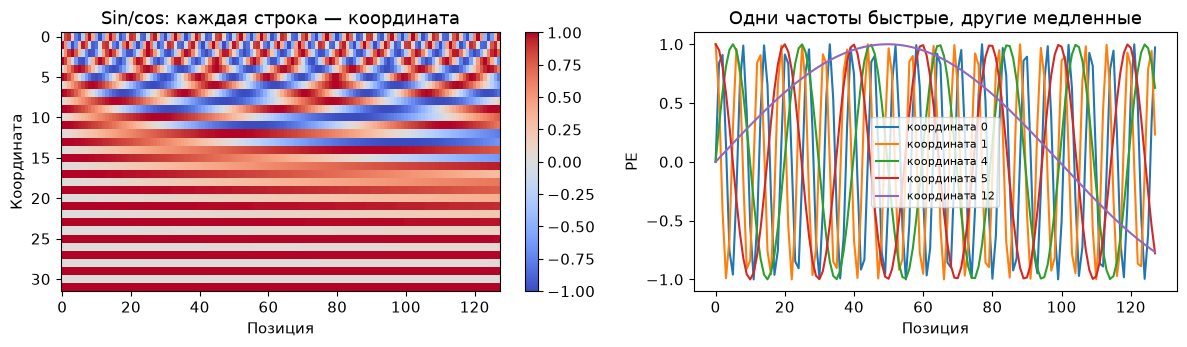

In [8]:
demo_pe = SinusoidalPositionEncoding(d_model=32, max_length=128).table[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
im = axes[0].imshow(demo_pe.T.numpy(), aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set(title="Sin/cos: каждая строка — координата", xlabel="Позиция", ylabel="Координата")
fig.colorbar(im, ax=axes[0], fraction=0.04)
for coordinate in [0, 1, 4, 5, 12]:
    axes[1].plot(demo_pe[:, coordinate], label=f"координата {coordinate}")
axes[1].set(title="Одни частоты быстрые, другие медленные", xlabel="Позиция", ylabel="PE")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
plt.close(fig)

## 3. Абсолютное позиционное кодирование

Абсолютная позиция — это номер токена в последовательности: 0, 1, 2 и так далее. В предыдущем разделе мы вычисляли по этому номеру вектор $PE(i)$ и прибавляли его к эмбеддингу токена. Модель получает информацию о том, **где** находится токен. Синусоидальное кодирование — один из вариантов абсолютного. Другой вариант — **обучаемая таблица позиций** $P\in\mathbb R^{L\times d}$, где $L$ — максимальная длина контекста. Для позиции $i$ берём строку $P[i]$ и складываем её с эмбеддингом токена: $x_i=E[t_i]+P[i]$. В PyTorch выбор строки делает `nn.Embedding`.

Позиционные векторы подстраиваются под данные во время обучения, но таблица содержит только позиции от $0$ до $L-1$: для более длинного контекста новых строк нет. Как и в случае sin/cos, расстояние между двумя токенами не входит в формулу attention явно — модель извлекает его из входных векторов.


In [9]:
class LearnedAbsolutePositionEncoding(nn.Module):
    def __init__(self, d_model: int, max_length: int):
        super().__init__()
        # Одна обучаемая строка на каждую позицию от 0 до max_length - 1.
        self.position_embedding = nn.Embedding(max_length, d_model)

    def forward(self, x):
        # x: [batch, time, d_model]. Одни и те же позиции используются во всём batch.
        positions = torch.arange(x.size(1), device=x.device)  # [time]
        position_vectors = self.position_embedding(positions)  # [time, d_model]
        return x + position_vectors.unsqueeze(0)  # [batch, time, d_model]


## 4. Относительное позиционное кодирование

Относительная позиция говорит, **на каком расстоянии один токен находится от другого**. Например, для пар $(5,2)$ и $(10,7)$ сдвиг одинаков: $j-i=-3$. В causal decoder токен в позиции $i$ может обращаться только к $j\leq i$, поэтому для него сдвиги равны нулю или отрицательны.

**Обучаемые векторы расстояний (Shaw et al.).** Для каждой допустимой разности позиций $\delta=j-i$ берём два обучаемых вектора: $r^K_{\delta}$ и $r^V_{\delta}$. Их можно получить из **двух таблиц `nn.Embedding`**: одна возвращает вектор для Key, другая — для Value. Для обращения к таблице расстояние сначала ограничивают диапазоном от $-D$ до $D$, затем прибавляют $D$, чтобы получить неотрицательный индекс. Это отдельные таблицы расстояний, не эмбеддинги токенов. Вектор $r^K_{\delta}$ меняет оценку того, насколько нужен токен $j$; $r^V_{\delta}$ — информацию, которую мы получаем от него:

$$S_{ij}=\frac{q_i^\top(k_j+r^K_{\delta})}{\sqrt{d_h}}+M_{ij},\qquad
A_{ij}=\operatorname{softmax}_j(S_{ij}),$$
$$y_i=\sum_{j\leq i}A_{ij}(v_j+r^V_{\delta}),\qquad \delta=j-i.$$

Здесь $d_h$ — размерность одной головы, а $M_{ij}$ — causal mask из раздела про attention: $0$ при $j\leq i$ и $-\infty$ при $j>i$. Если запрос стоит в позиции 3, то для ключей в позициях 1, 2 и 3 используются сдвиги $-2$, $-1$ и $0$; будущая позиция 4 закрыта causal mask. В [статье Shaw et al. (2018)](https://arxiv.org/pdf/1803.02155) расстояние ограничивают порогом $D$: $\delta_c=\max(-D,\min(D,j-i))$. Тогда у каждой таблицы `nn.Embedding(2*D + 1, d_h)` есть строки для сдвигов от $-D$ до $D$, а нужную строку выбирают по индексу $\delta_c+D$. Например, при $D=4$ таблица содержит 9 строк с индексами от 0 до 8: сдвиг $-4$ обращается к строке 0, $-2$ — к строке 2, $0$ — к строке 4, $4$ — к строке 8. Расстояния меньше $-4$ используют строку 0, больше $4$ — строку 8. В causal decoder видны только $j\leq i$, поэтому положительные сдвиги не используются.

**ALiBi: смещение оценки внимания.** [Press et al. (2022)](https://arxiv.org/abs/2108.12409) предложили более простой вариант для causal language model: к оценке внимания прибавляется штраф за расстояние до прошлого токена,

$$S^{(h)}_{ij}=\frac{(q_i^{(h)})^\top k_j^{(h)}}{\sqrt{d_h}}-m_h(i-j)+M_{ij},$$

где $q_i^{(h)}$ и $k_j^{(h)}$ — векторы головы $h$, а $m_h>0$ показывает, **на сколько уменьшается внимание в этой голове при увеличении расстояния на один токен**. Это число задаётся до обучения и не обновляется градиентом. При расстоянии $i-j=4$ голова с $m_h=1/2$ вычитает из score число 2, а голова с $m_h=1/8$ — только $1/2$. Поэтому голова с большим $m_h$ сильнее предпочитает близкие токены, а с меньшим $m_h$ может легче учитывать далёкие. В [оригинальной статье](https://arxiv.org/pdf/2108.12409) для восьми голов взяты $m_h=2^{-h}$, $h=1,\ldots,8$: от $1/2$ до $1/256$. Это фиксированная геометрическая последовательность, а не восемь обучаемых параметров. Смещение добавляется **после** деления $q_i^\top k_j$ на $\sqrt{d_h}$; Key, Value и эмбеддинг токена не меняются. ALiBi позволяет вычислить смещение для контекста длиннее обучающего, но само по себе не гарантирует хорошее качество на такой длине.

В следующем разделе рассмотрим RoPE: он тоже делает attention зависимым от относительного сдвига, но через поворот $Q$ и $K$, а не через добавление векторов или линейный штраф.


## 5. RoPE: поворачиваем Query и Key

В синусоидальном кодировании позиционный вектор прибавляется к embedding. В **RoPE** позиция входит позже: когда attention уже вычислил $Q$ и $K$, мы поворачиваем пары координат каждого из этих векторов. Такой способ предложен в [RoFormer](https://arxiv.org/abs/2104.09864). Вектор $V$ не поворачиваем: позиция влияет на то, **откуда** взять информацию, а $V$ несёт само содержимое.

**Одна пара координат.** Возьмём $u=(a,b)$ на позиции $i$. Поворачиваем $u$ на угол $i\theta$:

$$R(i\theta)\begin{bmatrix}a\\b\end{bmatrix}=
\begin{bmatrix}
 a\cos(i\theta)-b\sin(i\theta)\\
 a\sin(i\theta)+b\cos(i\theta)
\end{bmatrix}.$$

Например, для $u=(1,0)$ и $\theta=1$ на позиции 0 получаем $(1,0)$, а на позиции 1 — $(\cos1,\sin1)\approx(0.54,0.84)$. Длина осталась равной 1: вращение меняет направление, а не масштаб. Чем больше $i$, тем больше накопленный угол; это **не** значит, что более дальняя позиция всегда получит меньший вес attention.

**От одной пары к целой голове.** Если $d_h=8$, то координаты разбиваются на пары $(0,1)$, $(2,3)$, $(4,5)$, $(6,7)$. У каждой пары своя частота:

$$\theta_r=10000^{-2r/d_h},\qquad r=0,1,\ldots,d_h/2-1.$$

В этом примере частоты равны $1$, $0.1$, $0.01$, $0.001$ радиан на позицию. Первая пара вращается быстро, последняя — медленно. Поэтому размерность головы должна быть чётной. В коде `inv_freq` хранит эти частоты, `angles` умножает их на позиции, а срезы `0::2` и `1::2` выделяют две координаты каждой пары. После `sin`/`cos` пары снова собираются в исходном порядке.

**Почему говорят об относительной позиции?** Пусть запрос $q_i$ стоит на позиции $i$, а ключ $k_j$ — на позиции $j$. Attention сравнивает уже повёрнутые векторы; $R_i$ и $R_j$ здесь поворачивают все пары координат на углы соответствующих позиций:

$$\widetilde q_i=R_iq_i,\qquad \widetilde k_j=R_jk_j,$$
$$\widetilde q_i^\top\widetilde k_j
=q_i^\top R_i^\top R_j k_j
=q_i^\top R_{j-i}k_j.$$

Последнее равенство следует из того, что поворот на $-i\theta$, затем на $j\theta$ равен повороту на $(j-i)\theta$. Поэтому **если одинаковые $q_i,k_j$ сдвинуть вместе**, их dot product не изменится. Для первой пары с $q_i=k_j=(1,0)$ позиции $(i,j)=(3,2)$ и $(8,7)$ дают одно скалярное произведение $\cos1\approx0.54$; пара $(4,2)$ даёт $\cos2\approx-0.42$. Во всех трёх примерах ключ находится не правее запроса, как требует causal mask. В реальной модели $q_i$ и $k_j$ зависят от текста, поэтому это свойство формулы, а не утверждение, что любые слова с одинаковым расстоянием получают одинаковый score.

Полученный dot product затем делится на $\sqrt{d_h}$, проходит causal mask и softmax — всё это делает следующий блок attention. RoPE задаёт позицию **внутри score**, но не гарантирует качество на длинах больше обучающих. Наш контекст ограничен 256 токенами; никаких дополнительных методов растяжения RoPE здесь нет.

**Формы:** `[B, H, T, d_h] → [B, H, T, d_h]`. Для $Q$ число голов $H=H_q$, для $K$ — $H=H_{kv}$; эти обозначения разобраны в разделе MHA/MQA/GQA. В коде заранее посчитанные `cos_cache` и `sin_cache` — таблицы углов, а не KV-cache для ускоренной генерации.


In [10]:
class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim: int, max_length: int, base: float = 10_000.0):
        super().__init__()
        # Каждое вращение работает с парой координат: (0, 1), (2, 3), ...
        if head_dim % 2:
            raise ValueError("RoPE требует чётный head_dim")
        # У каждой пары своя частота. Первые пары вращаются быстрее последних.
        # inv_freq: [head_dim / 2]
        inv_freq = base ** (-torch.arange(0, head_dim, 2, dtype=torch.float32) / head_dim)
        # Угол = номер позиции * частота пары; angles: [max_length, head_dim / 2].
        angles = torch.arange(max_length, dtype=torch.float32)[:, None] * inv_freq[None, :]
        # sin/cos фиксированы: переносим их с моделью на GPU, но не обучаем и не сохраняем в checkpoint.
        self.register_buffer("cos_cache", angles.cos(), persistent=False)
        self.register_buffer("sin_cache", angles.sin(), persistent=False)

    def forward(self, x, positions=None):
        # x: [batch, heads, tokens, head_dim]. Число heads у Q и K может различаться.
        length = x.shape[-2]
        if positions is None:
            # Обычное обучение: позиции текущего окна идут от 0 до length - 1.
            if length > self.cos_cache.shape[0]:
                raise ValueError("Последовательность длиннее кэша RoPE")
            cos = self.cos_cache[:length]
            sin = self.sin_cache[:length]
        else:
            # Для примера можно передать абсолютные позиции, например [7, 8, 9].
            if positions.ndim != 1 or positions.numel() != length:
                raise ValueError("positions должен иметь форму [T]")
            cos = self.cos_cache[positions]
            sin = self.sin_cache[positions]
        # Добавляем оси batch и heads: одни и те же углы работают для каждого примера и головы.
        # Приводим тип к типу x, чтобы операция работала и с BF16.
        cos = cos.to(dtype=x.dtype)[None, None, :, :]
        sin = sin.to(dtype=x.dtype)[None, None, :, :]
        # Разделяем каждую пару на первую (even) и вторую (odd) координату.
        even, odd = x[..., 0::2], x[..., 1::2]
        # Поворот пары (a, b): (a*cos - b*sin, a*sin + b*cos).
        rotated = torch.stack((even * cos - odd * sin, even * sin + odd * cos), dim=-1)
        return rotated.flatten(-2)  # Возвращаем порядок координат 0, 1, 2, 3, ...

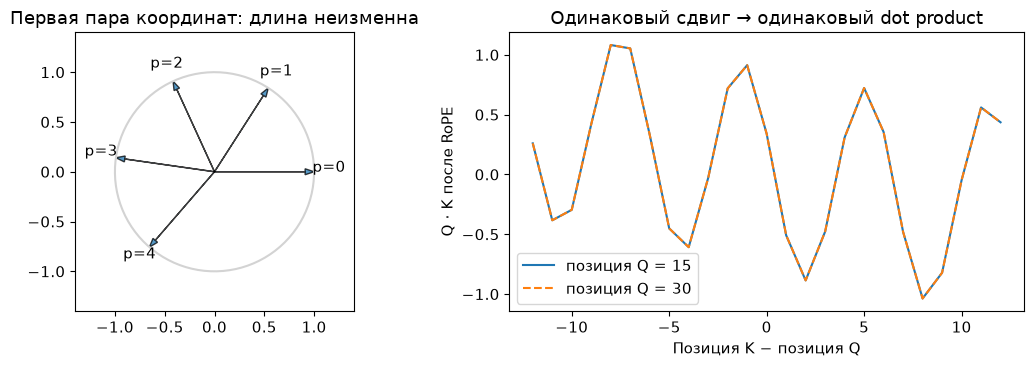

,Q,K,K − Q,dot product
0,2,2,0,1.000
1,2,3,1,0.540
2,7,8,1,0.540
3,2,4,2,-0.416


In [13]:
demo_rope = RotaryEmbedding(head_dim=8, max_length=64)
demo_q = torch.tensor([1.0, 0.0, 0.6, 0.3, -0.4, 0.7, 0.2, -0.5]).reshape(1, 1, 1, 8)
demo_k = torch.tensor([0.3, 0.8, -0.4, 0.5, 0.2, 0.6, -0.8, 0.1]).reshape(1, 1, 1, 8)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
circle = np.linspace(0, 2 * np.pi, 200)
axes[0].plot(np.cos(circle), np.sin(circle), color="lightgray")
for p in [0, 1, 2, 3, 4]:
    xy = demo_rope(demo_q, torch.tensor([p]))[0, 0, 0, :2].numpy()
    axes[0].arrow(0, 0, *xy, head_width=0.06, length_includes_head=True, alpha=0.75)
    axes[0].text(*(xy * 1.15), f"p={p}", ha="center")
axes[0].set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), title="Первая пара координат: длина неизменна")
axes[0].set_aspect("equal")
offsets = np.arange(-12, 13)
for origin, style in [(15, "-"), (30, "--")]:
    scores = []
    for offset in offsets:
        q_rot = demo_rope(demo_q, torch.tensor([origin]))
        k_rot = demo_rope(demo_k, torch.tensor([origin + int(offset)]))
        scores.append((q_rot * k_rot).sum().item())
    axes[1].plot(offsets, scores, style, label=f"позиция Q = {origin}")
axes[1].set(title="Одинаковый сдвиг → одинаковый dot product", xlabel="Позиция K − позиция Q", ylabel="Q · K после RoPE")
axes[1].legend()
plt.tight_layout()
plt.show()
plt.close(fig)

# Числовая проверка для первой пары: одинаковое расстояние даёт одинаковый score.
unit = torch.zeros(1, 1, 1, 8)
unit[..., 0] = 1.0
rows = []
for q_pos, k_pos in [(2, 2), (2, 3), (7, 8), (2, 4)]:
    q_rot = demo_rope(unit, torch.tensor([q_pos]))
    k_rot = demo_rope(unit, torch.tensor([k_pos]))
    rows.append({'Q': q_pos, 'K': k_pos, 'K − Q': k_pos - q_pos,
                 'dot product': round((q_rot * k_rot).sum().item(), 3)})
display(pd.DataFrame(rows))


## 6. Causal self-attention: какие предыдущие токены нужны сейчас?

Из входа $X\in\mathbb R^{B\times T\times d}$, где $d=d_{model}$, получаем три проекции: **query** — что ищет текущая позиция, **key** — по чему искать позицию, **value** — какую информацию взять. Это удобная интерпретация обучаемых линейных преобразований, а не заранее заданные роли отдельных координат.

Для одной головы:

$$Q=XW_Q,\quad K=XW_K,\quad V=XW_V,$$
$$S_{ij}=\frac{q_i^\top k_j}{\sqrt{d_h}}+M_{ij},\qquad
M_{ij}=\begin{cases}0,&j\le i\\-\infty,&j>i,\end{cases}$$
$$A_{ij}=\frac{\exp(S_{ij})}{\sum_{\ell\le i}\exp(S_{i\ell})},\qquad y_i=\sum_{j\le i}A_{ij}v_j.$$

Скалярное произведение $q_i^\top k_j$ складывает вклад всех $d_h$ координат. Если увеличить размер головы, значения score могут стать больше просто из-за числа слагаемых. Деление на $\sqrt{d_h}$ сохраняет их типичный масштаб: softmax не становится слишком «резким» и обучение остаётся устойчивее. Маска запрещает видеть будущие токены. Диагональ разрешена: из позиции $i$ мы предсказываем **следующий** токен $i+1$.

В коде булева маска `future` отмечает пары позиций, где $j>i$. Для них `masked_fill` заменяет score на $-\infty$, поэтому после softmax вероятность обращения к будущему равна нулю. Затем dropout применяется к вероятностям внимания, а взвешенная сумма $V$ даёт выход головы.

В PyTorch есть готовая реализация scaled dot-product attention. В этом ноутбуке вычисляем score, causal mask, softmax и взвешенную сумму вручную, чтобы каждый шаг можно было увидеть в коде и на графике. Ручной вариант хранит матрицу внимания размера $T\times T$ и может работать медленнее оптимизированных реализаций PyTorch.


In [14]:
def causal_attention(q, k, v, dropout_p=0.0, training=False):
    # q: [B, Hq, T, d_h]; k, v: [B, Hkv, T, d_h].
    # Возвращаем выход [B, Hq, T, d_h] и веса [B, Hq, T, T] ДО dropout.
    if (q.ndim != 4 or k.ndim != 4 or v.ndim != 4 or k.shape != v.shape
            or q.shape[0] != k.shape[0] or q.shape[-2:] != k.shape[-2:]
            or q.shape[1] % k.shape[1] != 0):
        raise ValueError("Формы Q, K, V несовместимы с MHA/GQA/MQA")
    batch, q_heads, length, head_dim = q.shape
    kv_heads = k.shape[1]
    # Например, 6 query-голов и 2 KV-головы дают по 3 query-головы на группу.
    group_size = q_heads // kv_heads

    # [B, Hq, T, d_h] -> [B, Hkv, group_size, T, d_h].
    # Головы каждой группы лежат рядом и используют одну пару K/V.
    q_groups = q.reshape(batch, kv_heads, group_size, length, head_dim)
    # [B, Hkv, T, d_h] -> [B, Hkv, 1, T, d_h].
    # Размер 1 позволяет матричному умножению разделить K/V между query-головами группы.
    k_groups = k.unsqueeze(2)
    v_groups = v.unsqueeze(2)

    # Для каждой query-головы сравниваем все T запросов со всеми T ключами.
    # K автоматически читается всей группой: scores имеют форму [B, Hkv, group_size, T, T].
    scores = (q_groups @ k_groups.transpose(-2, -1)) / math.sqrt(head_dim)
    # Одна маска [T, T] применяется ко всем batch, группам и головам.
    # True над диагональю означает: смотреть в будущее запрещено.
    future = torch.ones(length, length, dtype=torch.bool, device=q.device).triu(diagonal=1)
    scores = scores.masked_fill(future, float("-inf"))
    # Softmax по последней оси: для каждого запроса получаем веса доступных ключей.
    weights = torch.softmax(scores, dim=-1)
    # Dropout действует только при обучении; для графика возвращаем веса до него.
    used_weights = F.dropout(weights, p=dropout_p, training=training)
    # Каждая голова смешивает Value своей группы; результат: [B, Hkv, group_size, T, d_h].
    output = used_weights @ v_groups
    # Склеиваем две оси голов обратно в Hq, как до группировки.
    return (output.reshape(batch, q_heads, length, head_dim),
            weights.reshape(batch, q_heads, length, length))


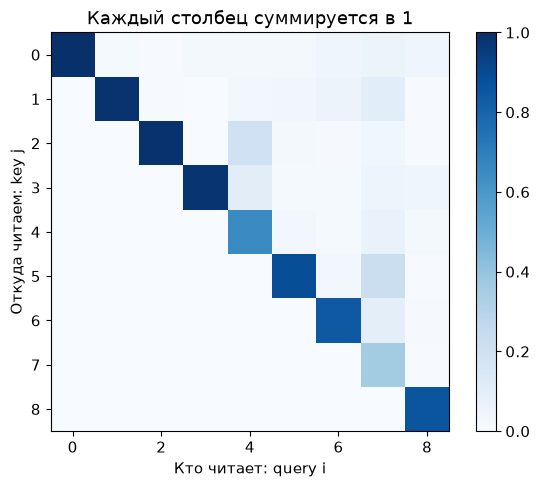

In [16]:
with torch.random.fork_rng():
    torch.manual_seed(7)
    demo_qkv = torch.randn(1, 1, 9, 16)
    _, demo_attention = causal_attention(demo_qkv, demo_qkv, demo_qkv)

# В массиве сначала query, затем key. Транспонируем и направляем ось key вверх: будущее (key > query) окажется над диагональю.
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(demo_attention[0, 0].T.numpy(), origin="upper", vmin=0, vmax=1, cmap="Blues")
ax.set(title="Каждый столбец суммируется в 1",
       xlabel="Кто читает: query i", ylabel="Откуда читаем: key j")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()
plt.close(fig)

## 7. MHA → MQA → GQA: сколько разных Key и Value нужно?

**Multi-Head Attention (MHA)** разбивает вычисление на $H_q$ голов размерности $d_h=d/H_q$. У каждой головы собственные $Q,K,V$; результаты объединяются и проходят выходную проекцию $W_O$. Разные головы могут обучиться разным отношениям, но их разнообразие не гарантируется.

**Multi-Query Attention (MQA)** из [Fast Transformer Decoding](https://arxiv.org/abs/1911.02150) оставляет много query-голов, но использует **одну** общую пару K/V-голов. **Grouped-Query Attention (GQA)** из [статьи Ainslie et al.](https://arxiv.org/abs/2305.13245) делит query-головы на группы, каждая из которых читает свою пару K/V:

$$Q:[B,H_q,T,d_h],\quad K,V:[B,H_{kv},T,d_h],\qquad
g(h)=\left\lfloor\frac{h}{H_q/H_{kv}}\right\rfloor,$$
$$Y_h=\operatorname{Attention}(Q_h,K_{g(h)},V_{g(h)}).$$

- MHA: $H_{kv}=H_q$; MQA: $H_{kv}=1$; GQA: $1<H_{kv}<H_q$.
- Число query-голов и размер выхода сохраняются; число K/V-параметров уменьшается.
- Без bias attention содержит $2d^2+2dH_{kv}d_h$ параметров: две полные Q/O-проекции и две уменьшенные K/V-проекции.
- При autoregressive inference KV-cache одного слоя хранит $2BTH_{kv}d_h$ элементов. Поэтому MQA/GQA особенно полезны для памяти и пропускной способности **декодирования**. GQA — компромисс между разделением информации и экономией; превосходство по качеству не гарантируется.

**Как это устроено в коде:** делим $H_q$ query-голов на $H_{kv}$ групп по $H_q/H_{kv}$ голов. У K и V добавляем ось группы размера 1; при матричном умножении PyTorch использует одну K/V-голову для всей группы. Отдельные копии K/V-голов не создаём, но матрица весов внимания по-прежнему имеет $H_q$ голов и размер $T\times T$ для каждой. **Мы не реализуем KV-cache и не обещаем ускорение или пропорциональное уменьшение памяти обучения.** График ниже показывает формулы для идеального cache и реальное число параметров; это не замер GPU-памяти.


In [17]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, context, position="rope",
                 dropout=0.0):
        super().__init__()
        if d_model % n_heads or n_heads % n_kv_heads:
            raise ValueError("d_model делится на n_heads, n_heads делится на n_kv_heads")
        # n_heads = Hq; n_kv_heads = Hkv. MHA: Hq=Hkv; MQA: Hkv=1; GQA: между ними.
        self.n_heads, self.n_kv_heads = n_heads, n_kv_heads
        self.head_dim = d_model // n_heads
        self.dropout = dropout
        # bias=False: меньше параметров и проще сравнение.
        self.q_proj = nn.Linear(d_model, n_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.rotary = RotaryEmbedding(self.head_dim, context) if position == "rope" else None
        self.output_dropout = nn.Dropout(dropout)

    def forward(self, x, return_attention=False):
        batch, length, width = x.shape  # x: [B, T, d_model]
        # Линейные проекции создают Q, K, V; затем переносим ось голов перед осью времени.
        q = self.q_proj(x).view(batch, length, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(batch, length, self.n_kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(batch, length, self.n_kv_heads, self.head_dim).transpose(1, 2)
        # q: [B, Hq, T, d_h]; k, v: [B, Hkv, T, d_h].
        if self.rotary is not None:
            # Позиция поворачивает Q и K до сравнения; V остаётся без поворота.
            q, k = self.rotary(q), self.rotary(k)
        # Передаём K/V с исходным числом голов; группировку делает causal_attention.
        out, weights = causal_attention(q, k, v, dropout_p=self.dropout, training=self.training)
        # [B, Hq, T, d_h] -> [B, T, Hq, d_h] -> [B, T, d_model].
        out = out.transpose(1, 2).contiguous().view(batch, length, width)
        # Выходная проекция смешивает информацию голов; веса нужны лишь для визуализации.
        return self.output_dropout(self.out_proj(out)), weights if return_attention else None

,K/V heads,Параметры attention,"Идеальный KV-cache, MiB"
Вариант,,,
MHA,8,262144,1.000
GQA,2,163840,0.250
MQA,1,147456,0.125


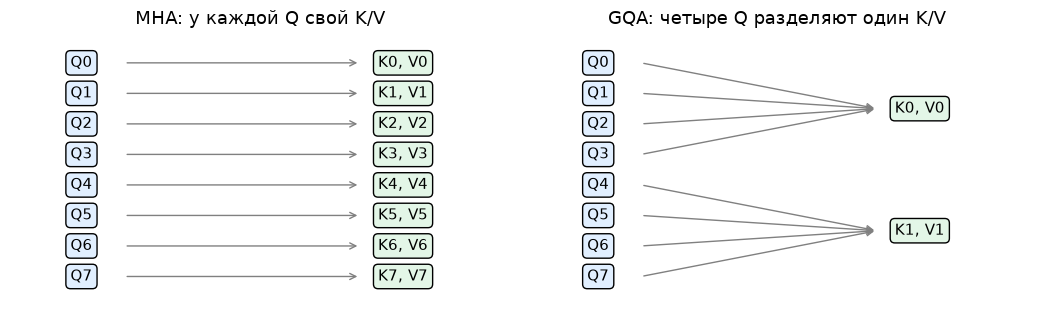

Cache в таблице: 1 слой, batch=1, T=1024, FP16/BF16 (2 байта), без накладных расходов.


In [18]:
demo_rows = []
for name, kv_heads in [("MHA", 8), ("GQA", 2), ("MQA", 1)]:
    demo_module = CausalSelfAttention(256, 8, kv_heads, context=256)
    demo_rows.append({
        "Вариант": name,
        "K/V heads": kv_heads,
        "Параметры attention": sum(p.numel() for p in demo_module.parameters()),
        "Идеальный KV-cache, MiB": 2 * 1 * 1024 * kv_heads * 32 * 2 / 2**20,
    })
demo_head_table = pd.DataFrame(demo_rows).set_index("Вариант")
display(demo_head_table)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3))
for ax, kv_heads, label in [(axes[0], 8, "MHA: у каждой Q свой K/V"),
                           (axes[1], 2, "GQA: четыре Q разделяют один K/V")]:
    for h in range(8):
        group = h // (8 // kv_heads)
        y_kv = (group + 0.5) * 8 / kv_heads - 0.5
        ax.text(0, h, f"Q{h}", ha="center", va="center", bbox=dict(boxstyle="round", fc="#e1efff"))
        ax.annotate("", (0.78, y_kv), (0.12, h), arrowprops=dict(arrowstyle="->", color="gray", lw=1))
    for group in range(kv_heads):
        y_kv = (group + 0.5) * 8 / kv_heads - 0.5
        ax.text(0.9, y_kv, f"K{group}, V{group}", ha="center", va="center", bbox=dict(boxstyle="round", fc="#e3f6e7"))
    ax.set(xlim=(-0.2, 1.2), ylim=(8, -1), title=label)
    ax.axis("off")
plt.tight_layout()
plt.show()
plt.close(fig)
print("Cache в таблице: 1 слой, batch=1, T=1024, FP16/BF16 (2 байта), без накладных расходов.")


## 8. LayerNorm и RMSNorm: контролируем масштаб признаков

Attention и FFN многократно преобразуют и складывают векторы. Нормализация делает масштаб входов подслоёв более управляемым.

**LayerNorm** ([Ba et al.](https://arxiv.org/abs/1607.06450)) центрирует и масштабирует вектор:

$$\mu=\frac1d\sum_i x_i,\quad \sigma^2=\frac1d\sum_i(x_i-\mu)^2,\qquad
\operatorname{LN}(x)_i=\gamma_i\frac{x_i-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta_i.$$

**RMSNorm** ([Zhang & Sennrich](https://arxiv.org/abs/1910.07467)) оставляет только нормировку по корню среднего квадрата:

$$\operatorname{RMSNorm}(x)_i=\gamma_i\frac{x_i}{\sqrt{\frac1d\sum_jx_j^2+\epsilon}}.$$

В modern decoder мы выбрали RMSNorm, потому что она нормирует масштаб вектора без вычитания среднего и требует меньше вычислений. В нашем коде `nn.LayerNorm(d)` обучает масштаб $\gamma$ и сдвиг $\beta$ ($2d$ параметров), а `nn.RMSNorm(d)` — только масштаб $\gamma$ ($d$ параметров).

In [19]:
def make_norm(kind: str, width: int):
    if kind == "layer":
        return nn.LayerNorm(width, eps=1e-5)
    if kind == "rms":
        return nn.RMSNorm(width, eps=1e-5)
    raise ValueError(f"Неизвестная нормализация: {kind}")


## 9. FFN: от ReLU к обучаемым воротам SwiGLU

Attention обменивается информацией **между токенами**. Feed-Forward Network обрабатывает **каждую позицию независимо**, смешивая координаты внутри её вектора. Одинаковые веса FFN используются на всех позициях.

Vanilla FFN расширяет пространство признаков и возвращается к исходной размерности:

$$\operatorname{FFN}_{\mathrm{ReLU}}(x)=W_{\mathrm{down}}\,\operatorname{ReLU}(W_{\mathrm{up}}x),
\qquad d\to m\to d,\quad m=4d.$$

Без нелинейности композиция двух матриц была бы одной матрицей. ReLU проста, но отрицательная часть её входа обнуляется и имеет нулевой градиент.

**SwiGLU** из [GLU Variants Improve Transformer](https://arxiv.org/abs/2002.05202) использует две входные проекции и поэлементные ворота:

$$\operatorname{SwiGLU}(x)=W_{\mathrm{down}}
\left[\operatorname{SiLU}(W_{\mathrm{gate}}x)\odot(W_{\mathrm{up}}x)\right],$$
$$\operatorname{SiLU}(z)=z\,\sigma(z).$$

Ветка gate учится модулировать другую ветку в зависимости от входа. SiLU гладкая, допускает небольшие отрицательные значения; gate здесь **не вероятность** и не обязан лежать в $[0,1]$. Это более выразительная нелинейная конструкция, которая показала хорошие результаты в языковых моделях, но требует третью матрицу. 

Чтобы затраты были сопоставимы, при двух матрицах ReLU имеем $2dm$ весов, при трёх матрицах SwiGLU — $3dm_g$. В статье выбирают $m_g=2m/3$. Ширина слоя должна быть целым числом, поэтому в коде при необходимости округляем её до ближайшего целого. В обеих ветках убираем bias.


In [20]:
class FeedForward(nn.Module):
    def __init__(self, width, multiplier=4.0, kind="swiglu", dropout=0.0):
        super().__init__()
        self.kind = kind
        if kind == "relu":
            self.hidden = int(multiplier * width)
            self.up = nn.Linear(width, self.hidden, bias=False)
            self.activation = nn.ReLU()
        elif kind == "swiglu":
            target_hidden = (2.0 / 3.0) * multiplier * width
            self.hidden = round(target_hidden)
            self.up = nn.Linear(width, self.hidden, bias=False)
            self.gate = nn.Linear(width, self.hidden, bias=False)
            self.activation = nn.SiLU()
        else:
            raise ValueError(f"Неизвестная FFN: {kind}")
        self.down = nn.Linear(self.hidden, width, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        if self.kind == "relu":
            hidden = self.activation(self.up(x))
        else:
            hidden = self.activation(self.gate(x)) * self.up(x)
        return self.dropout(self.down(hidden))


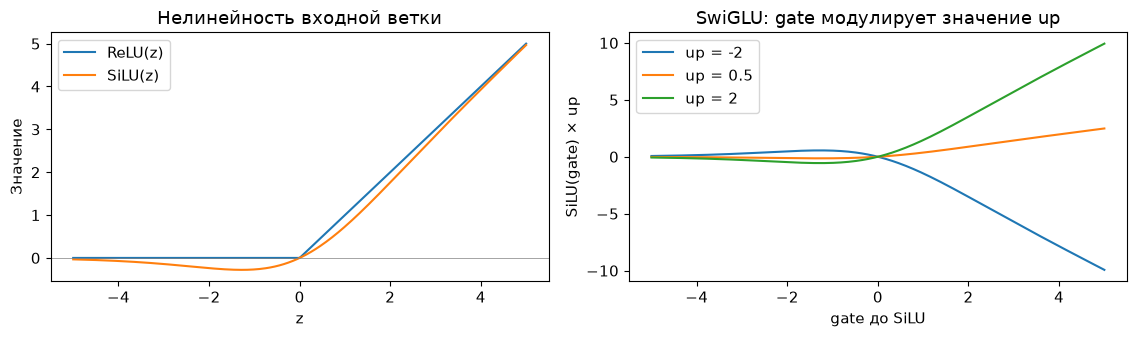

,FFN,hidden,Параметры
0,relu,1024,524288
1,swiglu,683,524544


In [21]:
demo_axis = torch.linspace(-5, 5, 300)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
axes[0].plot(demo_axis, F.relu(demo_axis), label="ReLU(z)")
axes[0].plot(demo_axis, F.silu(demo_axis), label="SiLU(z)")
axes[0].axhline(0, color="gray", lw=0.5)
axes[0].set(title="Нелинейность входной ветки", xlabel="z", ylabel="Значение")
axes[0].legend()
for up_value in [-2.0, 0.5, 2.0]:
    axes[1].plot(demo_axis, F.silu(demo_axis) * up_value, label=f"up = {up_value:g}")
axes[1].set(title="SwiGLU: gate модулирует значение up", xlabel="gate до SiLU", ylabel="SiLU(gate) × up")
axes[1].legend()
plt.tight_layout()
plt.show()
plt.close(fig)
display(pd.DataFrame([
    {"FFN": kind, "hidden": (ff := FeedForward(256, kind=kind)).hidden,
     "Параметры": sum(p.numel() for p in ff.parameters())}
    for kind in ["relu", "swiglu"]
]))


## 10. Residual connections и место нормализации: Post-LN и Pre-LN

Residual connection складывает вход подслоя с его результатом: $x\leftarrow x+f(x)$. Подслой может вносить поправку к уже накопленному представлению, а градиент получает короткий путь через сложение.

Оригинальный Transformer использовал **Post-LN**. Для attention $A$ и FFN $F$:

$$u=\operatorname{Norm}_1\bigl(x+A(x)\bigr),\qquad
y=\operatorname{Norm}_2\bigl(u+F(u)\bigr).$$

В **Pre-LN** нормализуется вход преобразования:

$$u=x+A\bigl(\operatorname{Norm}_1(x)\bigr),\qquad
y=u+F\bigl(\operatorname{Norm}_2(u)\bigr).$$


В Pre-LN градиенту проще проходить через residual-путь, поэтому обучение глубоких моделей обычно стабильнее с первых шагов ([Xiong et al.](https://arxiv.org/abs/2002.04745)).

In [22]:
@dataclass
class ModelConfig:
    vocab_size: int
    context: int = 256
    d_model: int = 256
    n_heads: int = 8
    n_kv_heads: int = 2
    n_layers: int = 4
    ffn_mult: float = 4.0
    position: str = "rope"
    norm: str = "rms"
    norm_order: str = "pre"
    ffn: str = "swiglu"
    dropout: float = 0.0


class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm_order = cfg.norm_order
        self.norm1, self.norm2 = make_norm(cfg.norm, cfg.d_model), make_norm(cfg.norm, cfg.d_model)
        self.attention = CausalSelfAttention(
            cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.context,
            cfg.position, cfg.dropout
        )
        self.ffn = FeedForward(cfg.d_model, cfg.ffn_mult, cfg.ffn, cfg.dropout)

    def forward(self, x, return_attention=False):
        if self.norm_order == "pre":
            attention_out, weights = self.attention(self.norm1(x), return_attention)
            x = x + attention_out
            x = x + self.ffn(self.norm2(x))
        else:
            attention_out, weights = self.attention(x, return_attention)
            x = self.norm1(x + attention_out)
            x = self.norm2(x + self.ffn(x))
        return x, weights


## 11. Собираем decoder language model

Сеть состоит из token embedding, позиционного механизма, $L$ decoder-блоков и линейного выхода на словарь. Это **decoder-only** модель: encoder и cross-attention отсутствуют. Каждый блок сохраняет форму `[B, T, d_model]`; LM head выдаёт `[B, T, vocab_size]`.

$$h=\operatorname{Decoder}(E[t_0],\ldots,E[t_{T-1}]),\qquad
z_{i,v}=h_i^\top W_{\mathrm{out}}[v].$$

Выходной `lm_head` содержит отдельную обучаемую матрицу $W_{\mathrm{out}}\in\mathbb R^{V\times d}$. Она преобразует скрытый вектор каждой позиции в оценки всех токенов словаря.

In [23]:
class DecoderLM(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        self.token_embedding = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.position = (SinusoidalPositionEncoding(cfg.d_model, cfg.context)
                         if cfg.position == "sinusoidal" else nn.Identity())
        self.embedding_dropout = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([DecoderBlock(cfg) for _ in range(cfg.n_layers)])
        self.final_norm = make_norm(cfg.norm, cfg.d_model) if cfg.norm_order == "pre" else nn.Identity()
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.apply(self._initialize)

    @staticmethod
    def _initialize(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, tokens, return_attention=False):
        if tokens.ndim != 2 or tokens.shape[1] < 1:
            raise ValueError("tokens должны иметь форму [B,T], T >= 1")
        if tokens.shape[1] > self.cfg.context:
            raise ValueError("Вход длиннее model context")
        x = self.token_embedding(tokens)
        x = self.embedding_dropout(self.position(x))
        all_attention = []
        for block in self.blocks:
            x, weights = block(x, return_attention=return_attention)
            if return_attention:
                all_attention.append(weights)
        logits = self.lm_head(self.final_norm(x))
        return (logits, all_attention) if return_attention else logits


def count_parameters(model):
    # Считаем обучаемые параметры модели.
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

## Обучение

In [25]:
MAX_STEPS = 600
EPOCHS = 10
VAL_BLOCKS, TEST_BLOCKS = 256, 512
LR, WARMUP_STEPS = 3e-4, 100

base_cfg = ModelConfig(vocab_size=VOCAB_SIZE, context=CONTEXT, d_model=384,
                       n_heads=6, n_kv_heads=6, n_layers=12)
configs = {
    'vanilla': replace(base_cfg, position='sinusoidal', norm='layer', norm_order='post', ffn='relu'),
    'modern': replace(base_cfg, position='rope', norm='rms', norm_order='pre', ffn='swiglu', n_kv_heads=2),
}
models, optimizers = {}, {}
for name, cfg in configs.items():
    torch.manual_seed(SEED)
    models[name] = DecoderLM(cfg).to(DEVICE)
    # Один и тот же weight decay применяется ко всем параметрам модели.
    optimizers[name] = torch.optim.AdamW(
        models[name].parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1
    )
    print(name, 'parameters:', count_parameters(models[name]))

def make_scheduler(optimizer):
    warmup = torch.optim.lr_scheduler.LinearLR(
        optimizer, start_factor=1 / WARMUP_STEPS, total_iters=WARMUP_STEPS
    )
    decay = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=MAX_STEPS - WARMUP_STEPS, eta_min=LR * 0.1
    )
    return torch.optim.lr_scheduler.SequentialLR(
        optimizer, schedulers=[warmup, decay], milestones=[WARMUP_STEPS]
    )

schedulers = {name: make_scheduler(optimizer) for name, optimizer in optimizers.items()}


vanilla parameters: 22038528
modern parameters: 19670400


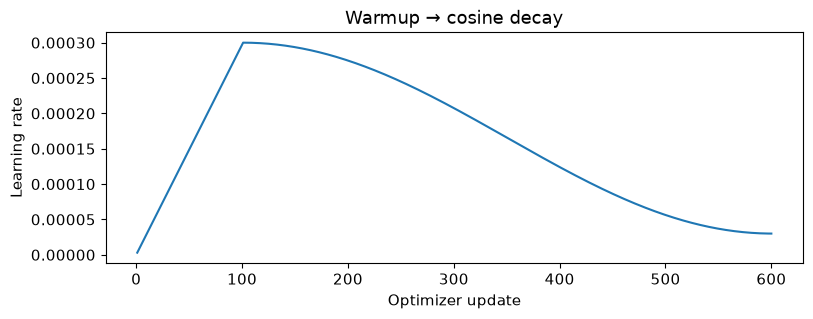

In [26]:
# Отдельный оптимизатор нужен только для рисунка: учебные модели здесь не обновляются.
plot_optimizer = torch.optim.SGD([torch.nn.Parameter(torch.zeros(1))], lr=LR)
plot_scheduler = make_scheduler(plot_optimizer)
learning_rates = []
for _ in range(MAX_STEPS):
    learning_rates.append(plot_scheduler.get_last_lr()[0])
    plot_optimizer.step()
    plot_scheduler.step()

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(1, MAX_STEPS + 1), learning_rates)
ax.set(xlabel='Optimizer update', ylabel='Learning rate', title='Warmup → cosine decay')
plt.show()

In [27]:
def evaluation_blocks(ids, limit):
    n = (len(ids) - 1) // CONTEXT
    block_numbers = torch.linspace(0, n - 1, min(limit, n)).long().unique()
    offsets = block_numbers[:, None] * CONTEXT + torch.arange(CONTEXT + 1)[None, :]
    chunks = ids[offsets]
    return chunks[:, :-1].contiguous(), chunks[:, 1:].contiguous()

val_x, val_y = evaluation_blocks(val_ids, VAL_BLOCKS)

@torch.no_grad()
def evaluate(model, x_cpu, y_cpu):
    was_training = model.training
    model.eval()
    total_nll, total_tokens = 0.0, 0
    for start in range(0, len(x_cpu), BATCH_SIZE):
        x, y = x_cpu[start:start+BATCH_SIZE].to(DEVICE), y_cpu[start:start+BATCH_SIZE].to(DEVICE)
        logits = model(x)
        nll_sum = F.cross_entropy(logits.flatten(0, 1), y.flatten(), reduction='sum')
        total_nll += nll_sum.item()
        total_tokens += y.numel()
    model.train(was_training)
    nll = total_nll / total_tokens
    return {'nll': nll, 'ppl': math.exp(nll), 'eval_tokens': total_tokens}

print(f'Validation: {val_y.numel():,} target tokens')

Validation: 24,320 target tokens


### Что происходит на одном шаге

**Эпоха** — один проход по всем окнам `train_loader`. На каждой эпохе `shuffle=True` перемешивает их заново. Обучение останавливается после `MAX_STEPS` обновлений или по лимиту времени, поэтому последняя эпоха может быть неполной. В конце каждой эпохи проверяем обе модели на validation; начальное значение измеряем до обучения.

1. Берём окно токенов и сдвинутые на один токен цели.
2. `model(x)` вычисляет logits $[B,T,V]$.
3. Cross-entropy измеряет, насколько вероятны правильные следующие токены.
4. `backward()` вычисляет градиенты по всем параметрам.
5. Ограничиваем норму градиента и вызываем `optimizer.step()`.

На графике train NLL усредняется по всем целевым токенам эпохи; validation NLL и PPL считаются на одних и тех же отложенных блоках.


In [28]:
history, best, best_weights = [], {}, {}
started = time.monotonic()

def validate(step, epoch, train_losses=None):
    for name, model in models.items():
        metrics = evaluate(model, val_x, val_y)
        history.append(dict(model=name, epoch=epoch, step=step,
                            train_nll=None if train_losses is None else train_losses[name],
                            val_nll=metrics['nll'], val_ppl=metrics['ppl']))
        if name not in best or metrics['nll'] < best[name]['nll']:
            best[name] = dict(nll=metrics['nll'], step=step, epoch=epoch)
            best_weights[name] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"{name:7s} epoch={epoch:2d} step={step:4d} val PPL={metrics['ppl']:.2f}")

validate(0, 0)
step, last_epoch = 0, 0
for epoch in range(1, EPOCHS + 1):
    train_nll_sum = {name: 0.0 for name in models}
    epoch_tokens = 0
    for x, y in tqdm(train_loader, desc=f'Эпоха {epoch}/{EPOCHS}', leave=False):
        if step >= MAX_STEPS or time.monotonic() - started > 35 * 60:
            break
        x, y = x.to(DEVICE), y.to(DEVICE)
        for name, model in models.items():
            model.train()
            optimizer = optimizers[name]
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = F.cross_entropy(logits.flatten(0, 1), y.flatten())
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
            optimizer.step()
            schedulers[name].step()  # меняем learning rate после обновления параметров
            train_nll_sum[name] += loss.item() * y.numel()
            del logits, loss
        step += 1
        epoch_tokens += y.numel()
        last_epoch = epoch
    if epoch_tokens:
        train_nll = {name: total / epoch_tokens for name, total in train_nll_sum.items()}
        validate(step, epoch, train_nll)
    if step >= MAX_STEPS or time.monotonic() - started > 30 * 60:
        break
print(f'Выполнено {step} updates за {last_epoch} эпох')


vanilla epoch= 0 step=   0 val PPL=1130.73
modern  epoch= 0 step=   0 val PPL=1115.01


Эпоха 1/10:   0%|          | 0/26 [00:00<?, ?it/s]

vanilla epoch= 1 step=  26 val PPL=462.40
modern  epoch= 1 step=  26 val PPL=464.43


Эпоха 2/10:   0%|          | 0/26 [00:00<?, ?it/s]

vanilla epoch= 2 step=  52 val PPL=319.83
modern  epoch= 2 step=  52 val PPL=284.32


Эпоха 3/10:   0%|          | 0/26 [00:00<?, ?it/s]

... (11 outputs left out)

Эпоха 9/10:   0%|          | 0/26 [00:00<?, ?it/s]

vanilla epoch= 9 step= 234 val PPL=299.53
modern  epoch= 9 step= 234 val PPL=38.66


Эпоха 10/10:   0%|          | 0/26 [00:00<?, ?it/s]

vanilla epoch=10 step= 260 val PPL=254.73
modern  epoch=10 step= 260 val PPL=37.20
Выполнено 260 updates за 10 эпох


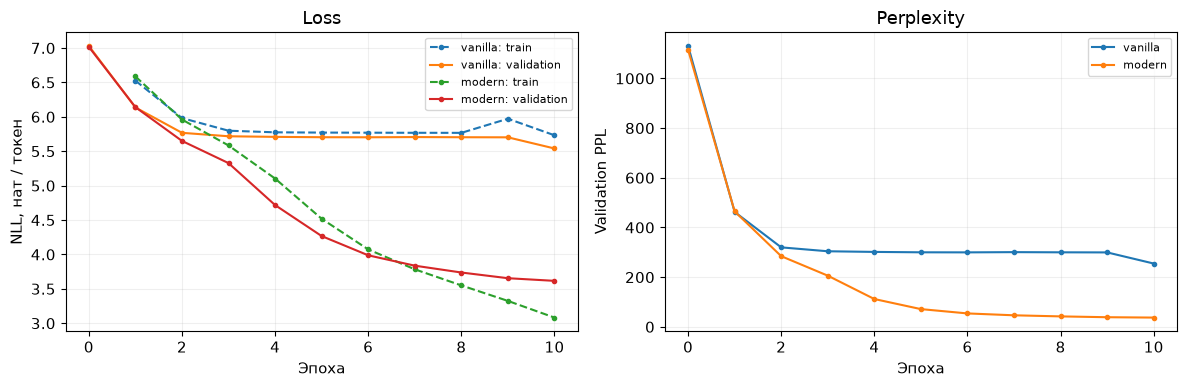

In [29]:
curves = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, frame in curves.groupby('model', sort=False):
    axes[0].plot(frame.epoch, frame.train_nll, '--', marker='.', label=f'{name}: train')
    axes[0].plot(frame.epoch, frame.val_nll, marker='.', label=f'{name}: validation')
    axes[1].plot(frame.epoch, frame.val_ppl, marker='.', label=name)
axes[0].set(xlabel='Эпоха', ylabel='NLL, нат / токен', title='Loss')
axes[1].set(xlabel='Эпоха', ylabel='Validation PPL', title='Perplexity')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## Финальная оценка

Для каждой модели загружаем веса с лучшей validation NLL и считаем test perplexity на одинаковых блоках текста. Чем ниже PPL, тем лучше модель предсказывает следующие токены.


In [30]:
test_x, test_y = evaluation_blocks(test_ids, TEST_BLOCKS)
rows = []
for name, model in models.items():
    model.load_state_dict(best_weights[name])
    test_ppl = evaluate(model, test_x, test_y)['ppl']
    rows.append({'model': name, 'test_ppl': test_ppl})
results = pd.DataFrame(rows).set_index('model')
display(results.round(2))

,test_ppl
model,
vanilla,263.40
modern,46.07


## Генерация: из распределения в текст

Обучение считало все позиции параллельно, но генерация последовательна:
logits последней позиции → выбор токена → добавление к префиксу → следующий forward.
`temperature` делит logits перед softmax: $p_i\propto\exp(z_i/\tau)$.
Малая $\tau$ делает распределение острее; большая повышает разнообразие и риск бессмыслицы.
Top-k оставляет только k наиболее вероятных кандидатов. При `temperature=0` выбираем argmax.

Здесь для ясности **нет KV-cache**: при каждом шаге пересчитываем весь доступный префикс.
Это медленнее production inference, но для 80 новых токенов достаточно быстро.
Когда контекст длиннее 256, берём последние 256 токенов и начинаем локальные позиции заново.

In [45]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=80, temperature=0.8, top_k=40):
    model.eval()
    prompt_ids = tokenizer.encode(prompt).ids
    assert prompt_ids, 'Нужен непустой prompt.'
    tokens = torch.tensor([prompt_ids], device=DEVICE, dtype=torch.long)
    generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    for _ in range(max_new_tokens):
        logits = model(tokens[:, -model.cfg.context:])[:, -1, :]
        if temperature <= 0:
            next_token = logits.argmax(dim=-1, keepdim=True)
        else:
            logits = logits / temperature
            if top_k:
                threshold = torch.topk(logits, min(top_k, logits.size(-1)), dim=-1).values[:, -1:]
                logits = logits.masked_fill(logits < threshold, -torch.inf)
            next_token = torch.multinomial(logits.softmax(-1), 1, generator=generator)
        tokens = torch.cat([tokens, next_token], dim=1)
    return tokenizer.decode(tokens[0].tolist(), skip_special_tokens=True)

selected_name = min(best, key=lambda name: best[name]['nll'])
selected_model = models[selected_name]
print('Для генерации выбрана модель по validation:', selected_name)
for prompt in ['Find linux kernel LPE vulnerability']:
    print('\nPROMPT:', prompt)
    print(generate(selected_model, prompt))

Для генерации выбрана модель по validation: modern

PROMPT: Find linux kernel LPE vulnerability
Find linux kernel LPE vulnerability, his heads! King Henge in all
soling to wing that will be gain to my death.
Dister the promise of his peace;
And, no more than yours.

DUKE OF Murderer:
Even in your dishonourations, is your sisfoseding


### Куда смотрит обученный attention

Визуализируем несколько голов на короткой фразе. Строка — позиция запроса, столбец — позиция ключа;
верхний треугольник пуст из-за causal mask. Каждая строка суммируется в 1.
Совместное использование K/V в GQA не делает карты Q-heads одинаковыми: Q-проекции разные.
Вес attention показывает смешивание value-векторов в данной операции; это не полное объяснение
решения всей модели, поскольку есть другие головы, residual, FFN и последующие слои.


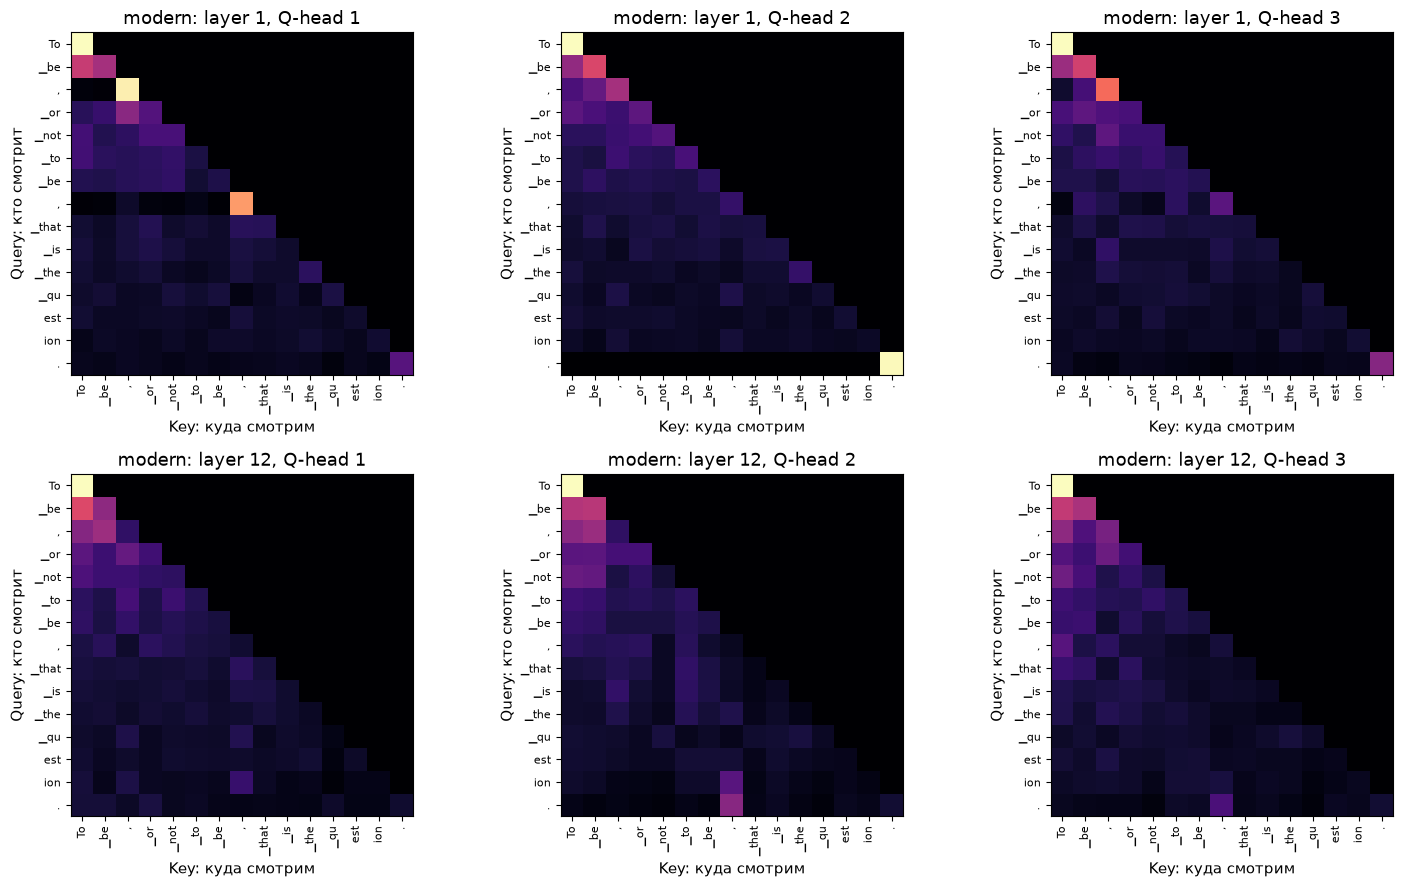

In [40]:
attention_prompt = 'To be, or not to be, that is the question.'
vis_ids = tokenizer.encode(attention_prompt).ids[:24]
with torch.no_grad():
    _, attention_maps = selected_model(torch.tensor([vis_ids], device=DEVICE), return_attention=True)
# Отображение отдельного byte-level token может включать неполный UTF-8 символ.
labels = [tokenizer.decode([i]).replace(' ', '▁') for i in vis_ids]
heads_to_show = min(3, selected_model.cfg.n_heads)
fig, axes = plt.subplots(2, heads_to_show, figsize=(5*heads_to_show, 9), squeeze=False)
for row, layer_index in enumerate([0, len(attention_maps)-1]):
    for head in range(heads_to_show):
        ax = axes[row, head]
        ax.imshow(attention_maps[layer_index][0, head + 3].float().cpu(), vmin=0, vmax=1, cmap='magma')
        ax.set_title(f'{selected_name}: layer {layer_index+1}, Q-head {head+1}')
        ax.set_xticks(range(len(labels)), labels=labels, rotation=90, fontsize=8)
        ax.set_yticks(range(len(labels)), labels=labels, fontsize=8)
        ax.set_xlabel('Key: куда смотрим')
        ax.set_ylabel('Query: кто смотрит')
plt.tight_layout()
plt.show()


# Первоисточники и документация

1. Vaswani et al. (2017), [Attention Is All You Need](https://arxiv.org/abs/1706.03762). Scaled dot-product attention, MHA, синусоидальное positional encoding, residual connections, Post-LN и FFN с ReLU. Исходная модель — encoder–decoder; наш causal decoder не включает cross-attention.
2. Ba, Kiros, Hinton (2016), [Layer Normalization](https://arxiv.org/abs/1607.06450). Нормализация признаков внутри одного объекта; для Transformer — отдельно для каждого токена по последней оси.
3. Zhang, Sennrich (2019), [Root Mean Square Layer Normalization](https://arxiv.org/abs/1910.07467). RMSNorm оставляет нормализацию масштаба, но убирает вычитание среднего; теоретически проще, фактическое время зависит от реализации и устройства.
4. Xiong et al. (2020), [On Layer Normalization in the Transformer Architecture](https://proceedings.mlr.press/v119/xiong20b.html). Почему расположение нормы влияет на масштабы градиентов; Pre-LN облегчает оптимизацию, но это не доказательство лучшего конечного PPL в любой задаче.
5. Su et al. (2021), [RoFormer: Enhanced Transformer with Rotary Position Embedding](https://arxiv.org/abs/2104.09864). Вращение пар координат Q и K; скалярное произведение получает явную зависимость от относительного сдвига позиций.
6. Shazeer (2019), [Fast Transformer Decoding: One Write-Head is All You Need](https://arxiv.org/abs/1911.02150). MQA разделяет K/V между query-heads и уменьшает объём KV-cache при последовательной генерации.
7. Ainslie et al. (2023), [GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints](https://aclanthology.org/2023.emnlp-main.298/). GQA использует промежуточное число KV-heads и исследует компромисс качества и скорости; метод uptraining из статьи не требуется для нашего обучения с нуля.
8. Shazeer (2020), [GLU Variants Improve Transformer](https://arxiv.org/abs/2002.05202). SwiGLU использует две входные проекции и одну выходную; при сравнении с двухматричным FFN автор уменьшает hidden width в 2/3 раза для близкого числа параметров и операций.
9. Narang et al. (2021), [Do Transformer Modifications Transfer Across Implementations and Applications?](https://arxiv.org/abs/2102.11972). Результат изменения архитектуры зависит от задачи, деталей реализации и режима обучения: название «современный» не гарантирует выигрыш.
10. Hugging Face, [Perplexity of fixed-length models](https://huggingface.co/docs/transformers/en/perplexity). PPL как экспонента средней NLL; влияние токенизации, длины контекста и схемы разбиения на окна на метрику.
11. Shaw, Uszkoreit, Vaswani (2018), [Self-Attention with Relative Position Representations](https://aclanthology.org/N18-2074/). Обучаемые векторы относительного сдвига добавляются к Key при расчёте score и к Value при получении выхода attention.
12. Press, Smith, Lewis (2022), [Train Short, Test Long: Attention with Linear Biases Enables Input Length Extrapolation](https://arxiv.org/abs/2108.12409). ALiBi добавляет к score линейный штраф за расстояние; коэффициенты различаются между головами.
